# IBM Applied Data Science Capstone — EDA Visualization Results

This notebook generates the six required Falcon 9 exploratory visualizations from the IBM course `dataset_part_2.csv`. It uses the course binary landing target (`Class`: 1 = successful first-stage landing, 0 = unsuccessful first-stage landing). It does not equate landing success with overall mission success.

All charts and summary tables are generated from the input CSV at execution time. No chart values are manually typed.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

DATA = Path('data/dataset_part_2.csv')
OUT = Path('outputs/eda')
OUT.mkdir(parents=True, exist_ok=True)
if not DATA.exists():
    raise FileNotFoundError(f'Course data not found: {DATA.resolve()}')

df = pd.read_csv(DATA)
df.columns = [str(c).strip() for c in df.columns]
required = {'FlightNumber','Date','PayloadMass','Orbit','LaunchSite','Class'}
missing = required - set(df.columns)
if missing:
    raise ValueError(f'Missing required columns: {sorted(missing)}; found {list(df.columns)}')

df['FlightNumber'] = pd.to_numeric(df['FlightNumber'], errors='coerce')
df['PayloadMass'] = pd.to_numeric(df['PayloadMass'], errors='coerce')
df['Class'] = pd.to_numeric(df['Class'], errors='coerce')
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
df = df.dropna(subset=['FlightNumber','Date','Orbit','LaunchSite','Class']).copy()
df['Class'] = df['Class'].astype(int)
if not set(df['Class'].unique()).issubset({0,1}):
    raise ValueError('Class must contain only 0 and 1.')
df['Year'] = df['Date'].dt.year
df['LandingOutcome'] = df['Class'].map({0:'Unsuccessful',1:'Successful'})
print('Validated Falcon 9 records:', len(df))
print('Features:', df.shape[1])
display(df.head())
display(df['LandingOutcome'].value_counts().to_frame('Records'))

Validated Falcon 9 records: 90
Features: 20


,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class,Year,LandingOutcome
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0,2010,Unsuccessful
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0,2012,Unsuccessful
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0,2013,Unsuccessful
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093,0,2013,Unsuccessful
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857,0,2013,Unsuccessful


,Records
LandingOutcome,
Successful,60
Unsuccessful,30


## 1. Flight number versus launch site

This categorical scatter/strip plot compares flight sequence and landing outcome at each launch site. Each point represents one historical launch record.

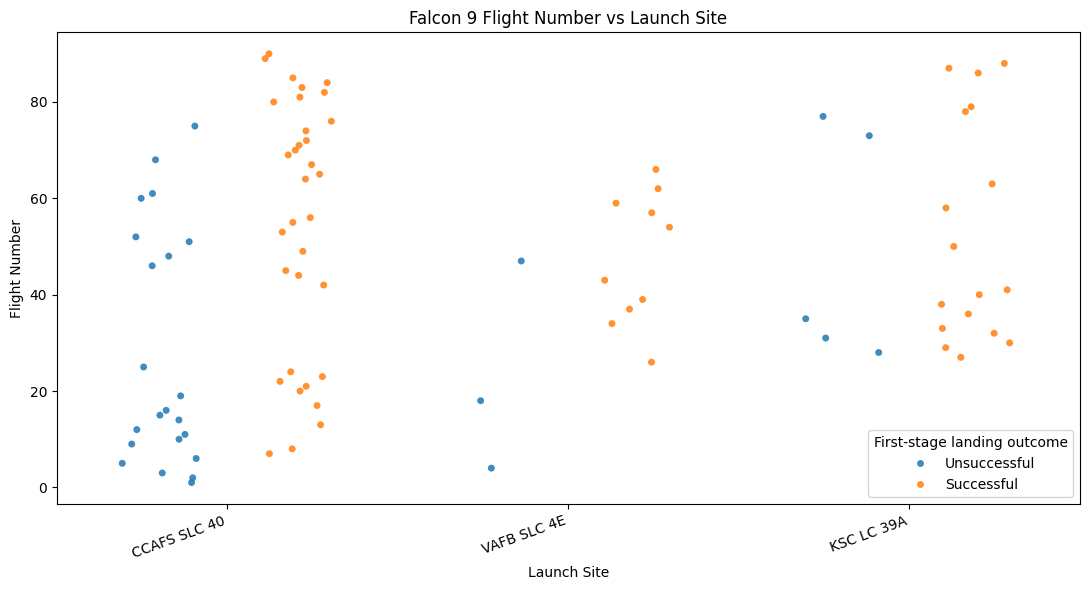

In [2]:
plt.figure(figsize=(11,6))
sns.stripplot(data=df, x='LaunchSite', y='FlightNumber', hue='LandingOutcome', dodge=True, jitter=0.22, alpha=0.85)
plt.title('Falcon 9 Flight Number vs Launch Site')
plt.xlabel('Launch Site')
plt.ylabel('Flight Number')
plt.xticks(rotation=20, ha='right')
plt.legend(title='First-stage landing outcome')
plt.tight_layout()
plt.savefig(OUT/'01_flight_number_vs_launch_site.png', dpi=220, bbox_inches='tight')
plt.show()

## 2. Payload mass versus launch site

This scatter/strip plot compares the payload-mass distribution by launch complex and distinguishes successful from unsuccessful first-stage landing outcomes. Missing payload masses are excluded only from this chart.

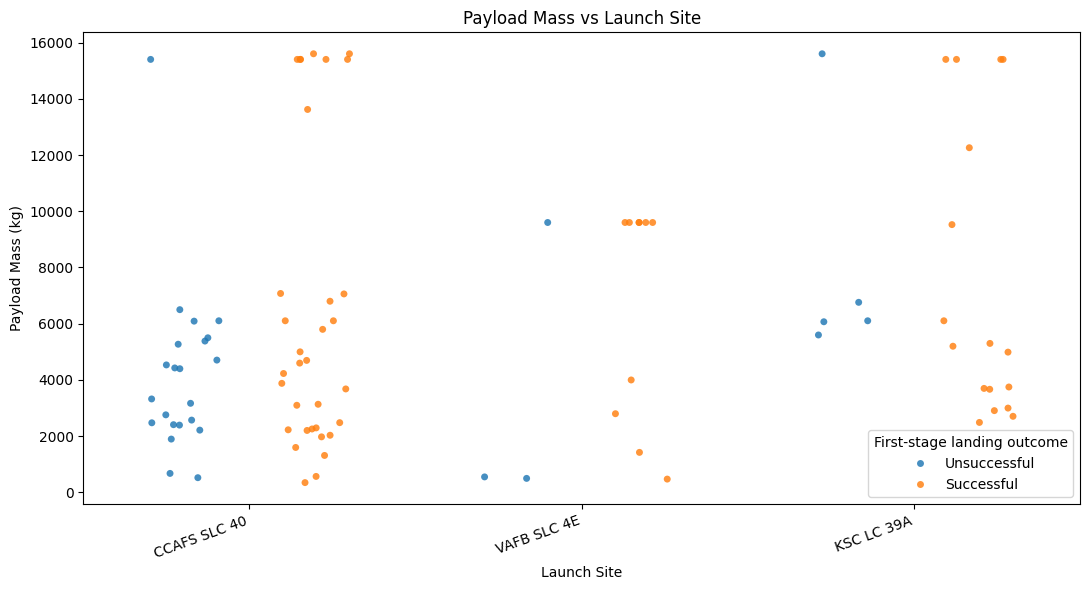

In [3]:
payload_df = df.dropna(subset=['PayloadMass']).copy()
plt.figure(figsize=(11,6))
sns.stripplot(data=payload_df, x='LaunchSite', y='PayloadMass', hue='LandingOutcome', dodge=True, jitter=0.22, alpha=0.82)
plt.title('Payload Mass vs Launch Site')
plt.xlabel('Launch Site')
plt.ylabel('Payload Mass (kg)')
plt.xticks(rotation=20, ha='right')
plt.legend(title='First-stage landing outcome')
plt.tight_layout()
plt.savefig(OUT/'02_payload_mass_vs_launch_site.png', dpi=220, bbox_inches='tight')
plt.show()

## 3. Landing success rate by orbit

The bar chart shows the observed mean of the binary landing target within each orbit category. Sample counts are displayed to make small groups visible. These are descriptive rates, not causal effects.

,Orbit,Launches,SuccessRatePct
0,ES-L1,1,100.0%
1,GEO,1,100.0%
3,HEO,1,100.0%
9,SSO,5,100.0%
10,VLEO,14,85.7%
5,LEO,7,71.4%
7,PO,9,66.7%
6,MEO,3,66.7%
4,ISS,21,61.9%
2,GTO,27,51.9%


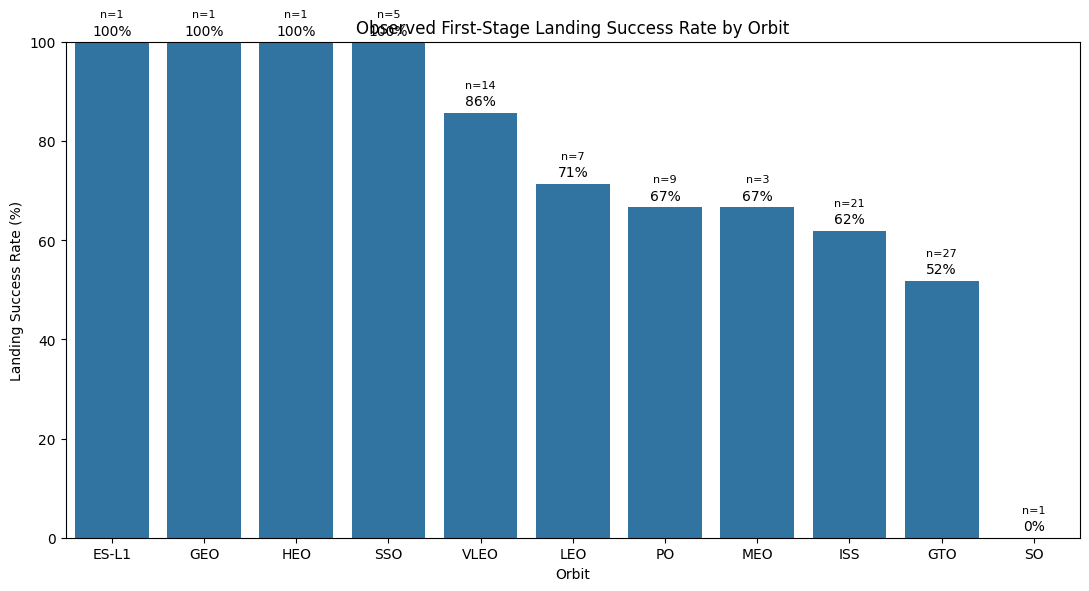

In [4]:
orbit_summary = df.groupby('Orbit', as_index=False).agg(
    Launches=('Class','size'), SuccessRate=('Class','mean')
)
orbit_summary['SuccessRatePct'] = orbit_summary['SuccessRate'] * 100
orbit_summary = orbit_summary.sort_values('SuccessRatePct', ascending=False)
display(orbit_summary[['Orbit','Launches','SuccessRatePct']].style.format({'SuccessRatePct':'{:.1f}%'}))
plt.figure(figsize=(11,6))
ax = sns.barplot(data=orbit_summary, x='Orbit', y='SuccessRatePct')
plt.title('Observed First-Stage Landing Success Rate by Orbit')
plt.xlabel('Orbit')
plt.ylabel('Landing Success Rate (%)')
plt.ylim(0,100)
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f%%', padding=3)
for i, row in orbit_summary.reset_index(drop=True).iterrows():
    ax.text(i, row['SuccessRatePct'] + 5, f"n={int(row['Launches'])}", ha='center', fontsize=8)
plt.tight_layout()
plt.savefig(OUT/'03_success_rate_by_orbit.png', dpi=220, bbox_inches='tight')
plt.show()

## 4. Flight number versus orbit

This categorical scatter plot examines the distribution of landing outcomes across flight numbers and orbit types.

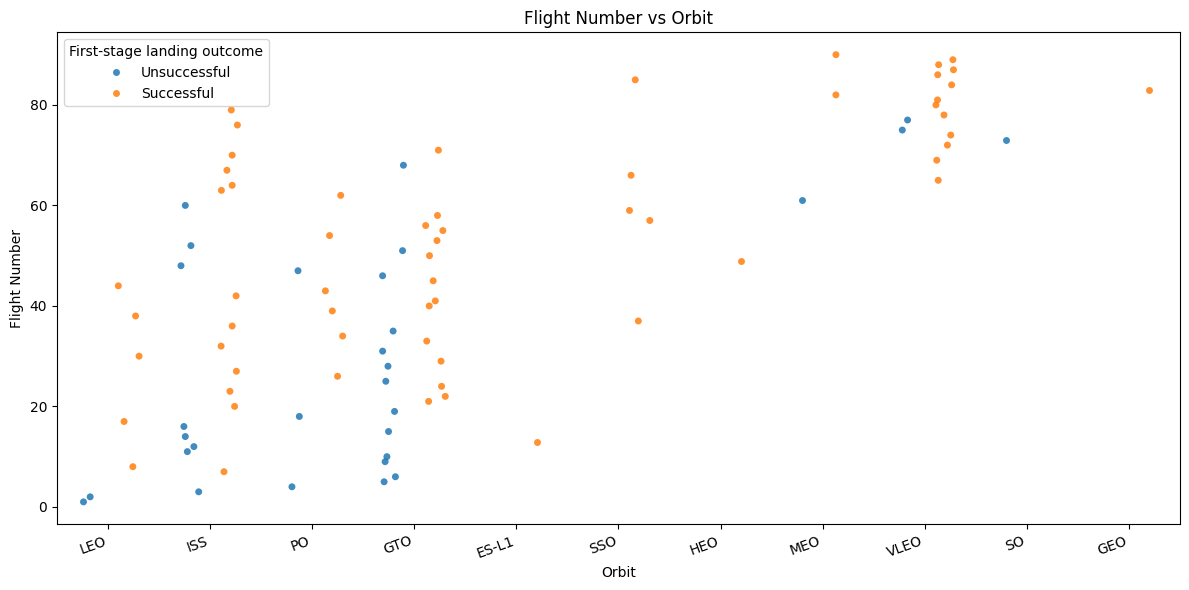

In [5]:
plt.figure(figsize=(12,6))
sns.stripplot(data=df, x='Orbit', y='FlightNumber', hue='LandingOutcome', dodge=True, jitter=0.22, alpha=0.85)
plt.title('Flight Number vs Orbit')
plt.xlabel('Orbit')
plt.ylabel('Flight Number')
plt.xticks(rotation=20, ha='right')
plt.legend(title='First-stage landing outcome')
plt.tight_layout()
plt.savefig(OUT/'04_flight_number_vs_orbit.png', dpi=220, bbox_inches='tight')
plt.show()

## 5. Payload mass versus orbit

This scatter/strip plot compares payload mass across orbit types and distinguishes the observed landing outcomes. Payload mass alone should not be interpreted as determining landing success.

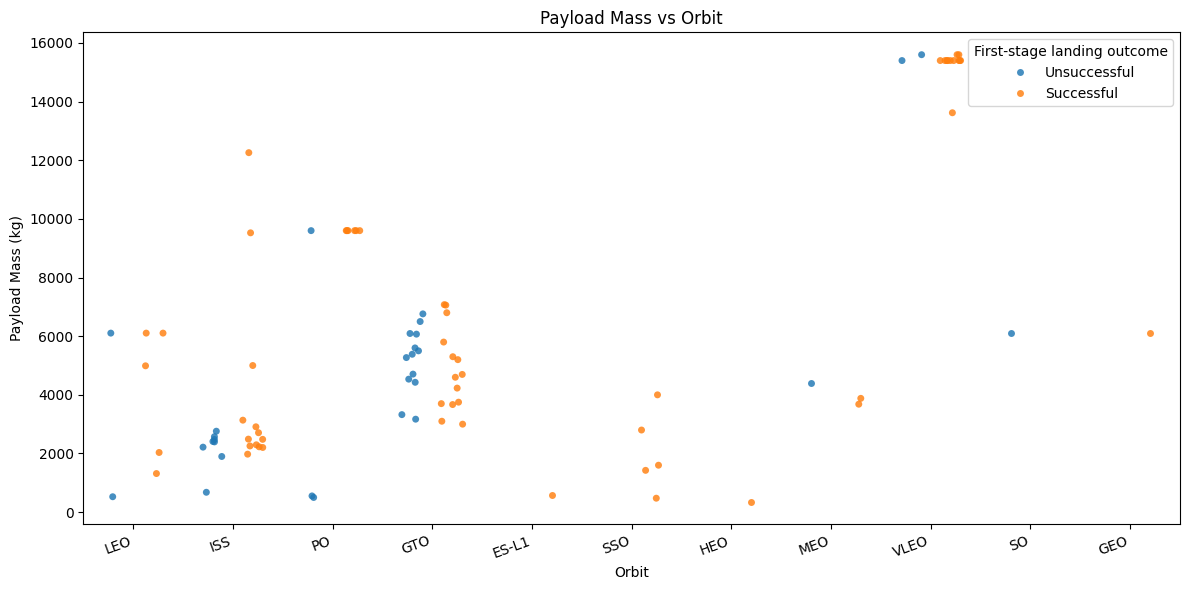

In [6]:
plt.figure(figsize=(12,6))
sns.stripplot(data=payload_df, x='Orbit', y='PayloadMass', hue='LandingOutcome', dodge=True, jitter=0.22, alpha=0.82)
plt.title('Payload Mass vs Orbit')
plt.xlabel('Orbit')
plt.ylabel('Payload Mass (kg)')
plt.xticks(rotation=20, ha='right')
plt.legend(title='First-stage landing outcome')
plt.tight_layout()
plt.savefig(OUT/'05_payload_mass_vs_orbit.png', dpi=220, bbox_inches='tight')
plt.show()

## 6. Yearly landing success trend

The yearly series is calculated as the mean of `Class` by calendar year. The annual launch count is also included, so rates based on very small yearly samples can be interpreted cautiously.

,Year,Launches,SuccessRatePct
0,2010,1,0.0%
1,2012,1,0.0%
2,2013,3,0.0%
3,2014,6,33.3%
4,2015,6,33.3%
5,2016,8,62.5%
6,2017,18,83.3%
7,2018,18,61.1%
8,2019,10,90.0%
9,2020,19,84.2%


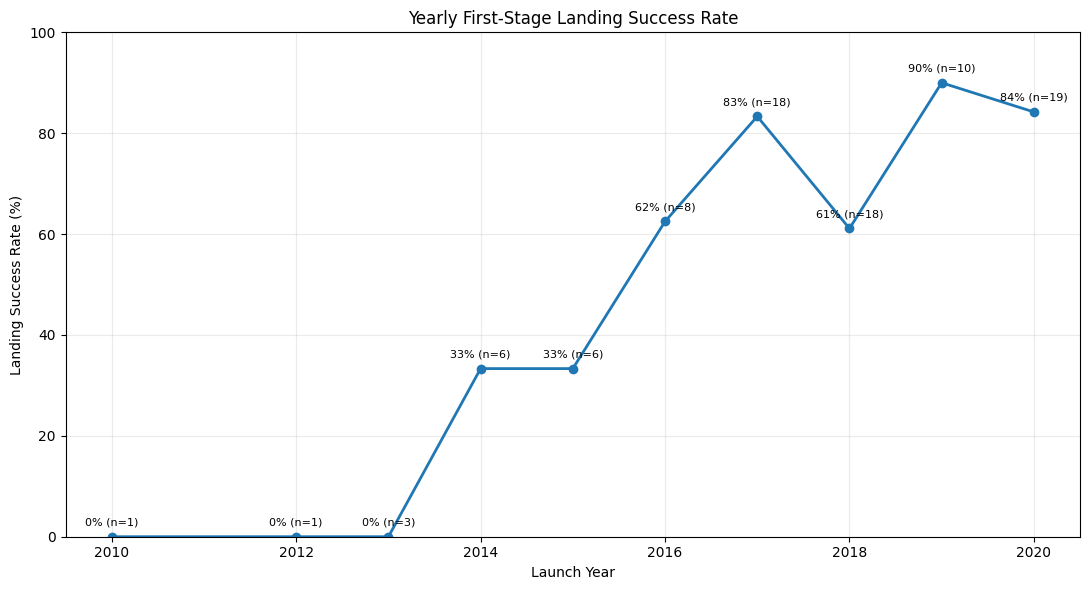

In [7]:
year_summary = df.groupby('Year', as_index=False).agg(
    Launches=('Class','size'), SuccessRate=('Class','mean')
)
year_summary['SuccessRatePct'] = year_summary['SuccessRate'] * 100
display(year_summary[['Year','Launches','SuccessRatePct']].style.format({'SuccessRatePct':'{:.1f}%'}))
fig, ax1 = plt.subplots(figsize=(11,6))
ax1.plot(year_summary['Year'], year_summary['SuccessRatePct'], marker='o', linewidth=2)
ax1.set_title('Yearly First-Stage Landing Success Rate')
ax1.set_xlabel('Launch Year')
ax1.set_ylabel('Landing Success Rate (%)')
ax1.set_ylim(0,100)
ax1.grid(True, alpha=0.25)
for _, row in year_summary.iterrows():
    ax1.annotate(f"{row['SuccessRatePct']:.0f}% (n={int(row['Launches'])})",
                 (row['Year'], row['SuccessRatePct']), xytext=(0,8),
                 textcoords='offset points', ha='center', fontsize=8)
plt.tight_layout()
plt.savefig(OUT/'06_yearly_success_trend.png', dpi=220, bbox_inches='tight')
plt.show()

## 7. Export reproducible summary tables

These CSV files support the slide interpretations and make the plotted rates auditable. All numerical conclusions should be copied from these executed outputs.

In [8]:
orbit_summary.to_csv(OUT/'orbit_success_summary.csv', index=False)
year_summary.to_csv(OUT/'yearly_success_summary.csv', index=False)
site_summary = df.groupby('LaunchSite', as_index=False).agg(
    Launches=('Class','size'), SuccessRate=('Class','mean')
)
site_summary['SuccessRatePct'] = site_summary['SuccessRate'] * 100
site_summary.to_csv(OUT/'launch_site_success_summary.csv', index=False)
display(site_summary.style.format({'SuccessRatePct':'{:.1f}%'}))
print('Six charts and three summary CSVs saved to', OUT.resolve())

,LaunchSite,Launches,SuccessRate,SuccessRatePct
0,CCAFS SLC 40,55,0.600000,60.0%
1,KSC LC 39A,22,0.772727,77.3%
2,VAFB SLC 4E,13,0.769231,76.9%


Six charts and three summary CSVs saved to /home/runner/work/Data-Science-Capstone-Project-Report/Data-Science-Capstone-Project-Report/outputs/eda
